<a href="https://colab.research.google.com/github/zw28623essex-dot/CE101_Team3/blob/main/main_load_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import numpy as np
import pandas as pd

!git clone https://github.com/zw28623essex-dot/CE101_Team3.git


fatal: destination path 'CE101_Team3' already exists and is not an empty directory.


In [22]:
num_cont_feat = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
cat_feat = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

In [23]:
df = pd.read_csv('/content/CE101_Team3/heart_cleaned.csv')
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [24]:
df = df.rename(columns={
    'cp': 'Chest_pain_type',
    'trestbps': 'Resting_BP',
    'thalach': 'Highest_HR'
})


In [25]:
df['sex'] = df['sex'].apply(lambda x: 'male' if x == 1 else 'female')
df['exang'] = df['exang'].map({1: 'Yes', 0:'No'})

In [26]:
print(df)

     age     sex  Chest_pain_type  Resting_BP  chol  fbs  restecg  Highest_HR  \
0     63    male                3         145   233    1        0         150   
1     37    male                2         130   250    0        1         187   
2     41  female                1         130   204    0        0         172   
3     56    male                1         120   236    0        1         178   
4     57  female                0         120   354    0        1         163   
..   ...     ...              ...         ...   ...  ...      ...         ...   
298   57  female                0         140   241    0        1         123   
299   45    male                3         110   264    0        1         132   
300   68    male                0         144   193    1        1         141   
301   57    male                0         130   131    0        1         115   
302   57  female                1         130   236    0        0         174   

    exang  oldpeak  slope  

In [27]:
df.shape


(303, 14)

In [28]:
df.columns


Index(['age', 'sex', 'Chest_pain_type', 'Resting_BP', 'chol', 'fbs', 'restecg',
       'Highest_HR', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [29]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   age              303 non-null    int64  
 1   sex              303 non-null    object 
 2   Chest_pain_type  303 non-null    int64  
 3   Resting_BP       303 non-null    int64  
 4   chol             303 non-null    int64  
 5   fbs              303 non-null    int64  
 6   restecg          303 non-null    int64  
 7   Highest_HR       303 non-null    int64  
 8   exang            303 non-null    object 
 9   oldpeak          303 non-null    float64
 10  slope            303 non-null    int64  
 11  ca               303 non-null    int64  
 12  thal             303 non-null    int64  
 13  target           303 non-null    int64  
dtypes: float64(1), int64(11), object(2)
memory usage: 33.3+ KB


In [30]:
df.describe()

,age,Chest_pain_type,Resting_BP,chol,fbs,restecg,Highest_HR,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [31]:
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values found!")

Missing values per column:
No missing values found!


In [32]:
missing_df = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
})
display(missing_df)

,Missing Values,Percentage (%)
age,0,0.0
sex,0,0.0
Chest_pain_type,0,0.0
Resting_BP,0,0.0
chol,0,0.0
fbs,0,0.0
restecg,0,0.0
Highest_HR,0,0.0
exang,0,0.0
oldpeak,0,0.0


/tmp/ipykernel_2308/2259652663.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[df['sex']=='female']['age'], rug=True, hist=True, label='female')
/tmp/ipykernel_2308/2259652663.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[df['sex']=='male']['age'], rug=True, hist=True, label='mal

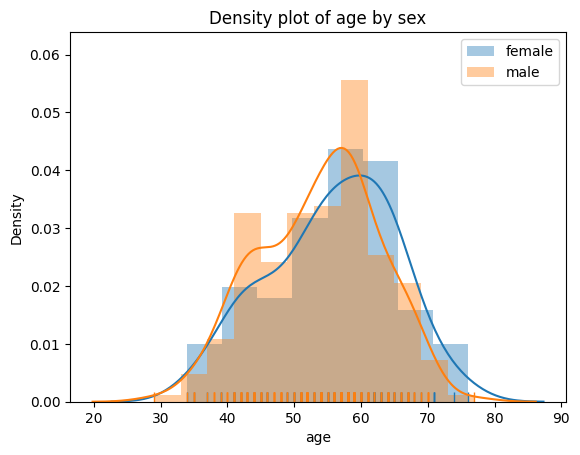

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.distplot(df[df['sex']=='female']['age'], rug=True, hist=True, label='female')
sns.distplot(df[df['sex']=='male']['age'], rug=True, hist=True, label='male')
plt.legend()
plt.title('Density plot of age by sex');

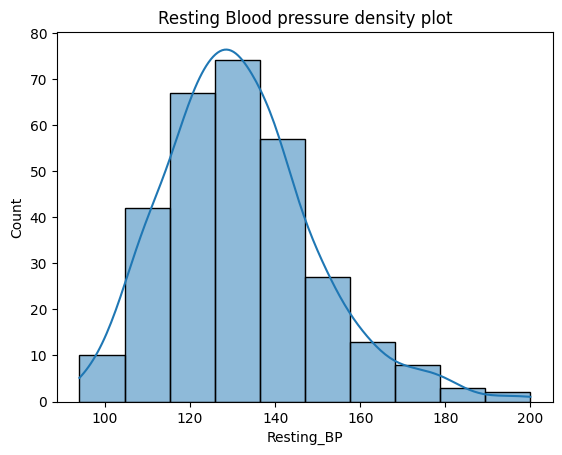

In [34]:
sns.histplot(df['Resting_BP'], bins=10, kde=True)
plt.title('Resting Blood pressure density plot');

In [35]:
df['sex'] = df['sex'].map({'female': 0, 'male': 1})
df['exang'] = df['exang'].map({'No': 0, 'Yes': 1})

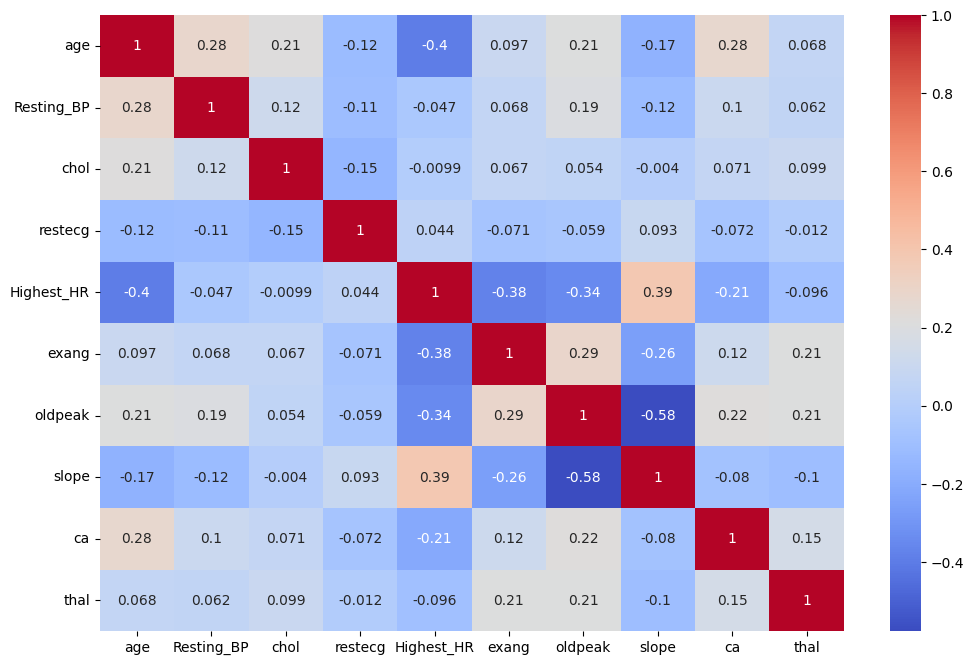

In [37]:
plt.figure(figsize=(12,8))
sns.heatmap(df.drop(['target', 'sex', 'Chest_pain_type', 'fbs'], axis=1).corr(), annot=True, cmap='coolwarm');